# Day model v2 — yesterday lags and deltas

Midnight freeze already knows yesterday, so this pack **keeps `demand_lag_48`**. Adds same-clock **1-day** weather deltas and `demand_lag_96` / `demand_delta_1d` (yesterday minus the day before). Adds **3h / 12h weather EMAs** (T, apparent T, shortwave, wind, HDD, CDD) plus 3h residuals so a front is not flattened into `temp_mean_24h`. Drops the 14d/3w demand extras that stole the root split on v1. Keeps week-over-week weather. Hour and week packs are unchanged.

Leads 0–24h only. Writes to `notebooks/day/v2/models`, not `data/models/day`. Optuna colsample is capped at 0.70–0.90. `PROMOTE = False`.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "energy_forecast").is_dir() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
HERE = ROOT / "notebooks" / "day" / "v2"
OUT_DIR = HERE / "models"
V1_DIR = ROOT / "notebooks" / "day" / "v1" / "models"
sys.path.insert(0, str(ROOT / "src"))

from energy_forecast import tune
from energy_forecast.data.demand import load_demand
from energy_forecast.evaluate import as_board_scored, board_naive_scale, overall_metrics, score
from energy_forecast.explain import explain_scored, mean_abs_shap, shap_source_share
from energy_forecast.features import (
    DAY_V1_FEATURES,
    DAY_V2_FEATURES,
    FEATURE_COLUMNS,
    attach_lookback_demand,
    attach_lookback_weather,
)
from energy_forecast.forecast import prepare_history
from energy_forecast.live import DAY, load_board, load_context_actuals
from energy_forecast.model import (
    DAY_MAX_LEAD_HOURS,
    load_day_models,
    load_models,
    predict_quantiles,
    split_training_frame,
    train_models,
)
from energy_forecast.modes import SHORT, resample_to_mode
from energy_forecast.regions import SERIES_ID
from energy_forecast.review import (
    _attach_frozen_and_weather,
    _ensure_calendar,
    _load_archive_weather,
    _pack_rows,
    _ready_predict_frame,
    _recompute_weather_features,
)
from energy_forecast.settlement import LONDON_TZ
from energy_forecast.tune import naive_scale_for_product

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda v: f"{v:,.1f}")
print("repo", ROOT)
print("write models to", OUT_DIR)
print("kept lag_48", "demand_lag_48" in DAY_V2_FEATURES)
print("no 3w mean", "demand_mean_3w" not in DAY_V2_FEATURES)
print("extras", [c for c in DAY_V2_FEATURES if c not in FEATURE_COLUMNS])
prod = load_day_models()
print("production day features", len(prod.features))

repo D:\energy-forecast
write models to D:\energy-forecast\notebooks/day/v2\models
kept lag_48 True
no 3w mean True
extras ['temp_delta_7d', 'temp_mean_24h_delta_7d', 'apparent_temp_delta_7d', 'hdd_delta_7d', 'cdd_delta_7d', 'shortwave_delta_7d', 'wind_delta_7d', 'cloud_delta_7d', 'shortwave_mean_24h', 'wind_mean_24h', 'temp_delta_1d', 'temp_mean_24h_delta_1d', 'apparent_temp_delta_1d', 'hdd_delta_1d', 'cdd_delta_1d', 'shortwave_delta_1d', 'wind_delta_1d', 'cloud_delta_1d', 'demand_lag_96', 'demand_delta_1d', 'temp_ema_3h', 'temp_ema_12h', 'apparent_temp_ema_3h', 'apparent_temp_ema_12h', 'shortwave_ema_3h', 'shortwave_ema_12h', 'wind_ema_3h', 'wind_ema_12h', 'hdd_ema_3h', 'hdd_ema_12h', 'cdd_ema_3h', 'cdd_ema_12h', 'temp_ema_resid_3h', 'shortwave_ema_resid_3h', 'wind_ema_resid_3h']
production day features 37


## 1. History

Previous Runs, leads ≤ 24h. Same split as notebook 03 day pack.

In [2]:
history = prepare_history()
train, holdout = split_training_frame(
    history, features=FEATURE_COLUMNS, max_lead_hours=DAY_MAX_LEAD_HOURS
)
_, holdout_v2 = split_training_frame(
    history, features=DAY_V2_FEATURES, max_lead_hours=DAY_MAX_LEAD_HOURS
)
scale = naive_scale_for_product(train, "short")
print("train", len(train), "holdout", len(holdout), "v2 holdout", len(holdout_v2))

train 91194 holdout 5090 v2 holdout 5090


## 2. Optuna

Hourly 24h holdout on `DAY_V2_FEATURES`. Study: `data/processed/optuna_day_v2.db`. `colsample_bytree` 0.70–0.90 so trees cannot always take every collinear lag. Does not overwrite `data/models/day`. Re-run the search cell to add trials.

In [3]:
PRODUCT = "day_v2"
N_TRIALS = 40
TRAIN_SAMPLE = None
USE_WANDB = False

tune_train, tune_holdout = tune.product_split(history, PRODUCT, train_sample=TRAIN_SAMPLE)
print(PRODUCT, "train", len(tune_train), "holdout", len(tune_holdout))

baseline = tune.baseline_params(PRODUCT)
print("baseline params", baseline)
base_models = tune.fit_trial(tune_train, PRODUCT, baseline, refit_full=False)
baseline_mae, baseline_metrics = tune.holdout_mae(tune_holdout, base_models, PRODUCT, train=tune_train)
print("baseline MAE", baseline_mae)
display(baseline_metrics)

study = tune.create_study(PRODUCT)
with tune.tracking_run(PRODUCT, study, wandb_on=USE_WANDB):
    study.optimize(tune.make_objective(tune_train, tune_holdout, PRODUCT), n_trials=N_TRIALS, show_progress_bar=True)
    tune.log_study_end(study, PRODUCT)
print("best MAE", study.best_value)
print("best params", study.best_params)
print("beats baseline", study.best_value < baseline_mae, "by", baseline_mae - study.best_value, "MW")

day_v2 train 90522 holdout 5090
baseline params {'learning_rate': 0.05, 'num_leaves': 47, 'min_child_samples': 30, 'subsample': 0.8, 'colsample_bytree': 0.8, 'n_estimators': 400}
baseline MAE 802.6429175513454


,split,n,mae,rmse,mape,bias,pinball_10,pinball_50,pinball_90,coverage_80,interval_width,skill_vs_climatology,rmsse,wrmsse
0,all,2546,802.6,"1,108.0",0.0,-13.7,200.5,401.3,192.1,0.8,"2,749.4",0.5,0.4,0.4


[I 2026-10-08 21:10:48,331] Using an existing study with `study_name='day_v2_mae'` instead of creating a new one.


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-08 21:11:15,807] Trial 40 finished with value: 815.5516490952879 and parameters: {'learning_rate': 0.02554111812234441, 'num_leaves': 66, 'min_child_samples': 11, 'subsample': 0.7141953696716312, 'colsample_bytree': 0.7329883213154056, 'n_estimators': 450}. Best is trial 38 with value: 802.4959163026499.
[I 2026-10-08 21:11:47,435] Trial 41 finished with value: 810.8127167084451 and parameters: {'learning_rate': 0.021825206320648785, 'num_leaves': 82, 'min_child_samples': 36, 'subsample': 0.7353677076943527, 'colsample_bytree': 0.7303620845275388, 'n_estimators': 500}. Best is trial 38 with value: 802.4959163026499.
[I 2026-10-08 21:12:11,017] Trial 42 finished with value: 802.4823994433749 and parameters: {'learning_rate': 0.03304485417502948, 'num_leaves': 57, 'min_child_samples': 39, 'subsample': 0.73009448658969, 'colsample_bytree': 0.704511623524376, 'n_estimators': 450}. Best is trial 42 with value: 802.4823994433749.
[I 2026-10-08 21:12:41,920] Trial 43 finished with 

KeyboardInterrupt: 

In [4]:
rows = pd.DataFrame(tune.study_trial_rows(study, PRODUCT))
display(rows.sort_values("mae").head(10))
best_path = HERE / "optuna_best.json"
best_payload = {key: study.best_params[key] for key in tune.PARAM_KEYS if key in study.best_params}
best_payload["holdout_mae"] = float(study.best_value)
best_path.write_text(json.dumps(best_payload, indent=2), encoding="utf-8")
print("wrote", best_path)

,product,trial,mae,best_mae_so_far,is_best,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,n_estimators,wrmsse,rmse,bias,coverage_80,interval_width,skill_vs_climatology
42,day_v2,42,802.5,802.5,True,0.0,57,39,0.7,0.7,450,0.4,"1,100.2",-20.8,0.8,"2,733.6",0.5
38,day_v2,38,802.5,802.5,False,0.0,74,16,0.7,0.7,500,0.4,"1,106.5",-33.6,0.8,"2,928.8",0.5
45,day_v2,45,804.1,802.5,False,0.0,53,37,0.7,0.7,400,0.4,"1,102.4",-16.2,0.8,"2,767.8",0.5
32,day_v2,32,804.6,804.6,False,0.0,68,34,0.7,0.7,500,0.4,"1,102.8",-32.0,0.8,"2,703.8",0.5
47,day_v2,47,804.7,802.5,False,0.0,53,41,0.7,0.7,400,0.4,"1,101.8",-19.2,0.8,"2,775.4",0.5
46,day_v2,46,804.9,802.5,False,0.0,59,40,0.8,0.7,450,0.4,"1,102.1",-38.1,0.8,"2,793.5",0.5
44,day_v2,44,805.0,802.5,False,0.0,54,22,0.7,0.7,450,0.4,"1,110.6",-40.3,0.8,"2,811.9",0.5
28,day_v2,28,805.1,805.1,False,0.0,50,33,0.8,0.7,450,0.4,"1,104.5",-18.7,0.8,"2,826.8",0.5
2,day_v2,2,808.9,808.9,False,0.1,32,22,0.7,0.8,350,0.4,"1,111.8",2.7,0.8,"2,773.4",0.5
16,day_v2,16,809.1,808.9,False,0.0,82,17,0.8,0.7,500,0.4,"1,109.6",-26.0,0.8,"2,899.8",0.5


wrote D:\energy-forecast\notebooks/day/v2\optuna_best.json


## 3. Train day v2

Full history, leads ≤ 24h. Uses `optuna_best.json` if you ran section 2. Does not overwrite `data/models/day`.

In [5]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
best_path = HERE / "optuna_best.json"
lgb_params = None
if best_path.exists():
    raw = json.loads(best_path.read_text(encoding="utf-8"))
    lgb_params = {key: raw[key] for key in tune.PARAM_KEYS if key in raw}
    print("using Optuna winner", lgb_params)
else:
    print("no optuna_best.json; stock LightGBM")

v2, metrics = train_models(
    history,
    model_dir=OUT_DIR,
    role="next_day",
    features=DAY_V2_FEATURES,
    max_lead_hours=DAY_MAX_LEAD_HOURS,
    lgb_params=lgb_params,
)
meta_path = OUT_DIR / "metadata.json"
meta = json.loads(meta_path.read_text(encoding="utf-8"))
meta["engineered_day"] = True
meta["yesterday_lags"] = True
if lgb_params:
    meta["optuna_params"] = lgb_params
meta_path.write_text(json.dumps(meta, indent=2), encoding="utf-8")
print("saved", OUT_DIR, "n features", len(v2.features), "lag_48", "demand_lag_48" in v2.features, "lag_96", "demand_lag_96" in v2.features)
metrics

using Optuna winner {'learning_rate': 0.03304485417502948, 'num_leaves': 57, 'min_child_samples': 39, 'subsample': 0.73009448658969, 'colsample_bytree': 0.704511623524376, 'n_estimators': 450}
saved D:\energy-forecast\notebooks/day/v2\models n features 72 lag_48 True lag_96 True


,metric,quantile,value
0,pinball,0.1,203.5
1,pinball,0.5,414.1
2,mae,0.5,828.3
3,pinball,0.9,189.3
4,coverage_80,0.8,0.8
5,interval_scale,0.8,2.1


## 4. Holdout (hourly, 24h)

In [6]:
from energy_forecast.model import load_models as load_from

v2 = load_from(OUT_DIR)
v1 = load_from(V1_DIR) if (V1_DIR / "metadata.json").exists() else None

def pack_metrics(frame, models, label):
    scored = resample_to_mode(score(frame, models), SHORT)
    out = overall_metrics(scored, scale_mse=scale)
    out.insert(0, "model", label)
    return out

rows = [pack_metrics(holdout, prod, "production day")]
if v1 is not None:
    _, holdout_v1 = split_training_frame(
        history, features=DAY_V1_FEATURES, max_lead_hours=DAY_MAX_LEAD_HOURS
    )
    rows.append(pack_metrics(holdout_v1, v1, "day v1 / 3w extras"))
rows.append(pack_metrics(holdout_v2, v2, "day v2 / yesterday"))
pd.concat(rows, ignore_index=True)

,model,split,n,mae,rmse,mape,bias,pinball_10,pinball_50,pinball_90,coverage_80,interval_width,skill_vs_climatology,rmsse,wrmsse
0,production day,all,2546,843.1,"1,109.6",0.0,-95.9,194.2,421.5,188.7,0.8,"2,895.6",0.5,0.4,0.4
1,day v1 / 3w extras,all,2546,816.7,"1,104.3",0.0,12.5,184.3,408.4,188.4,0.8,"2,456.3",0.5,0.4,0.4
2,day v2 / yesterday,all,2546,808.1,"1,106.5",0.0,11.0,199.4,404.0,184.1,0.8,"2,821.9",0.5,0.4,0.4


## 5. Last completed live days

Board day pack, every London day on the live board with actuals (not the dashboard’s last-3 clip). Archive weather + 22 days of demand so 7d weather and `lag_96` fill. `temp_delta_1d` should be finite on nearly every row.

In [7]:
demand_hist = load_demand(include_live=True)


def shap_ready(frame, models):
    out = _ensure_calendar(frame.copy().reset_index(drop=True))
    out["region_id"] = SERIES_ID
    out["timestamp"] = pd.to_datetime(out["timestamp"], utc=True)
    keep_ts = out["timestamp"].copy()
    work = attach_lookback_weather(out.drop(columns=["window_start"], errors="ignore"), _load_archive_weather())
    work = attach_lookback_demand(work, demand_hist, days=22)
    rebuilt = _recompute_weather_features(work)
    keys = ["timestamp", "lead_hours"] if "lead_hours" in out.columns else ["timestamp"]
    take = [c for c in models.features if c in rebuilt.columns]
    right_keys = [k for k in keys if k in rebuilt.columns]
    right = rebuilt.loc[:, list(dict.fromkeys([*right_keys, *take]))].drop_duplicates(right_keys, keep="last")
    merged = out.merge(right, on=right_keys, how="left", suffixes=("", "_rebuilt"))
    for column in models.features:
        rebuilt_col = f"{column}_rebuilt"
        if column not in merged.columns and rebuilt_col in merged.columns:
            merged[column] = merged[rebuilt_col]
        elif rebuilt_col in merged.columns:
            merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
                pd.to_numeric(merged[rebuilt_col], errors="coerce")
            )
    merged["region_id"] = SERIES_ID
    merged = merged.loc[pd.to_datetime(merged["timestamp"], utc=True).isin(set(keep_ts))].copy()
    return _ready_predict_frame(merged, models)


board = load_board()
ctx = load_context_actuals()
joined = _attach_frozen_and_weather(
    DAY,
    _pack_rows(DAY, board, ctx, day_days=None).dropna(subset=["actual_mw", "p50"]),
    _load_archive_weather(),
)
joined["timestamp"] = pd.to_datetime(joined["timestamp"], utc=True)
joined["region_id"] = SERIES_ID
print("live days", len(joined), joined["timestamp"].min(), "->", joined["timestamp"].max())
scale_live = board_naive_scale()


def metrics_row(frame, label, climatology):
    scored = as_board_scored(frame, climatology=climatology)
    out = overall_metrics(scored, scale_mse=scale_live)
    out.insert(0, "model", label)
    return out, scored


issued_tbl, _ = metrics_row(joined, "issued (board)", prod.climatology)
prod_in = shap_ready(joined, prod)
prod_hat = predict_quantiles(prod_in, prod)
prod_days = joined.copy()
prod_days[["p10", "p50", "p90"]] = prod_hat[["p10", "p50", "p90"]].to_numpy()
prod_tbl, _ = metrics_row(prod_days, "production day (re-score)", prod.climatology)
live_tbls = [issued_tbl, prod_tbl]
v1_days = None
if v1 is not None:
    v1_in = shap_ready(joined, v1)
    v1_hat = predict_quantiles(v1_in, v1)
    v1_days = joined.copy()
    v1_days[["p10", "p50", "p90"]] = v1_hat[["p10", "p50", "p90"]].to_numpy()
    v1_tbl, _ = metrics_row(v1_days, "day v1 / 3w extras", v1.climatology)
    live_tbls.append(v1_tbl)
v2_in = shap_ready(joined, v2)
print("v2 temp_delta_1d finite", float(pd.to_numeric(v2_in["temp_delta_1d"], errors="coerce").notna().mean()))
print("v2 demand_delta_1d finite", float(pd.to_numeric(v2_in["demand_delta_1d"], errors="coerce").notna().mean()))
v2_hat = predict_quantiles(v2_in, v2)
v2_days = joined.copy()
v2_days[["p10", "p50", "p90"]] = v2_hat[["p10", "p50", "p90"]].to_numpy()
v2_tbl, _ = metrics_row(v2_days, "day v2 / yesterday", v2.climatology)
live_tbls.append(v2_tbl)
pd.concat(live_tbls, ignore_index=True)

live days 138 2026-10-05 23:00:00+00:00 -> 2026-10-08 19:30:00+00:00


C:\Users\Admin\AppData\Local\Temp\ipykernel_125744\596562321.py:22: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_125744\596562321.py:22: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_125744\596562321.py:22: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, 

v2 temp_delta_1d finite 1.0
v2 demand_delta_1d finite 0.6521739130434783


C:\Users\Admin\AppData\Local\Temp\ipykernel_125744\596562321.py:22: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(
C:\Users\Admin\AppData\Local\Temp\ipykernel_125744\596562321.py:22: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  merged[column] = pd.to_numeric(merged[column], errors="coerce").combine_first(


,model,split,n,mae,rmse,mape,bias,pinball_10,pinball_50,pinball_90,coverage_80,interval_width,skill_vs_climatology,rmsse,wrmsse
0,issued (board),all,138,812.1,"1,036.0",0.0,424.2,219.3,406.0,133.9,0.9,"3,161.0",0.0,0.4,0.4
1,production day (re-score),all,138,853.7,"1,064.1",0.0,488.5,216.5,426.9,141.5,0.8,"3,104.7",0.0,0.5,0.4
2,day v1 / 3w extras,all,138,"1,040.9","1,249.2",0.0,764.2,223.4,520.5,208.8,0.7,"2,780.3",0.0,0.5,0.5
3,day v2 / yesterday,all,138,844.5,"1,045.6",0.0,621.4,219.8,422.2,140.3,0.8,"3,036.1",0.0,0.4,0.4


In [8]:
local = pd.to_datetime(joined["timestamp"], utc=True).dt.tz_convert(LONDON_TZ)
payload = {
    "day": local.dt.strftime("%a %d %b"),
    "actual": pd.to_numeric(joined["actual_mw"], errors="coerce"),
    "issued": pd.to_numeric(joined["p50"], errors="coerce"),
    "prod": pd.to_numeric(prod_days["p50"], errors="coerce"),
    "v2": pd.to_numeric(v2_days["p50"], errors="coerce"),
}
if v1_days is not None:
    payload["v1"] = pd.to_numeric(v1_days["p50"], errors="coerce")
daily = pd.DataFrame(payload)
rows = []
for day, g in daily.groupby("day", sort=False):
    row = {
        "day": day,
        "n": int(len(g)),
        "actual": float(g["actual"].mean()),
        "issued MAE": float((g["actual"] - g["issued"]).abs().mean()),
        "prod MAE": float((g["actual"] - g["prod"]).abs().mean()),
        "v2 MAE": float((g["actual"] - g["v2"]).abs().mean()),
    }
    if "v1" in g.columns:
        row["v1 MAE"] = float((g["actual"] - g["v1"]).abs().mean())
    rows.append(row)
pd.DataFrame(rows)

,day,n,actual,issued MAE,prod MAE,v2 MAE,v1 MAE
0,Tue 06 Oct,48,"26,608.9",578.8,674.8,526.0,697.9
1,Wed 07 Oct,48,"26,876.6",897.7,888.1,"1,126.7","1,065.2"
2,Thu 08 Oct,42,"26,125.4",980.7,"1,019.0",885.9,"1,405.2"


## 6. SHAP

v2 should keep `lag_48` as the main demand analog. `demand_delta_1d` / `temp_delta_1d` / `temp_ema_3h` should show up; `demand_mean_3w` should not.

Holdout |SHAP| share


model,day v2,production day
source,,
calendar,0.2,0.3
demand_lag,0.5,0.4
lead,0.0,0.0
weather,0.3,0.3


v2 top features


,feature,mean_abs_shap
0,demand_lag_48,"2,080.4"
1,demand_lag_336,"1,186.4"
2,day_of_week,636.9
3,demand_lag_96,226.9
4,wind_delta_1d,213.4
5,wind_delta_7d,202.6
6,shortwave_delta_1d,190.9
7,period_sin,169.2
8,is_weekend,156.5
9,settlement_period,147.2


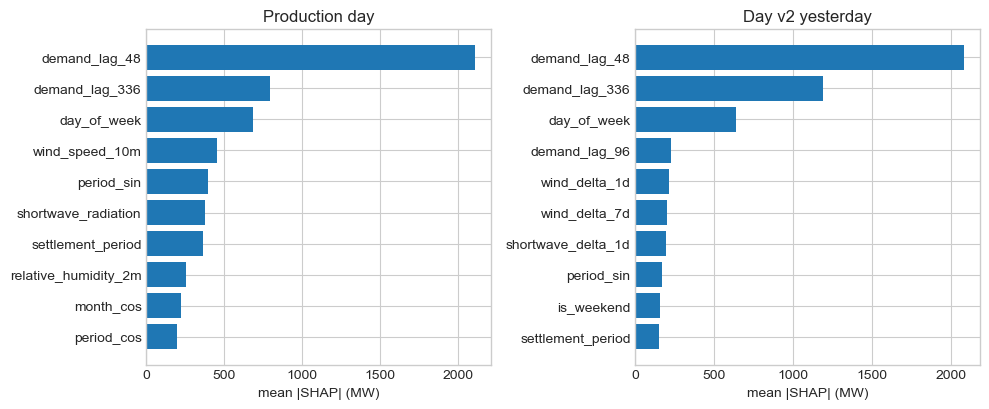

In [9]:
n = 2_500
need_p = [c for c in prod.features if c in holdout.columns]
need_v = [c for c in v2.features if c in holdout_v2.columns]
prod_s = holdout.dropna(subset=["demand_mw", *need_p]).sample(n, random_state=0)
v2_s = holdout_v2.dropna(subset=["demand_mw", *need_v]).sample(n, random_state=0)
if "region_id" not in prod_s.columns:
    prod_s["region_id"] = SERIES_ID
if "region_id" not in v2_s.columns:
    v2_s["region_id"] = SERIES_ID
prod_shap = explain_scored(predict_quantiles(prod_s, prod), prod)["mean"]
v2_shap = explain_scored(predict_quantiles(v2_s, v2), v2)["mean"]
share = pd.concat(
    [
        shap_source_share(prod_shap).assign(model="production day"),
        shap_source_share(v2_shap).assign(model="day v2"),
    ],
    ignore_index=True,
)
print("Holdout |SHAP| share")
display(share.pivot(index="source", columns="model", values="share"))
print("v2 top features")
display(mean_abs_shap(v2_shap, n=15))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, shap_df, title in (
    (axes[0], prod_shap, "Production day"),
    (axes[1], v2_shap, "Day v2 yesterday"),
):
    rank = mean_abs_shap(shap_df, n=10)
    ax.barh(rank["feature"].iloc[::-1], rank["mean_abs_shap"].iloc[::-1])
    ax.set_title(title)
    ax.set_xlabel("mean |SHAP| (MW)")
fig.tight_layout()

## 7. Promote (optional)

Copies day v2 over `data/models/day`. Week and hour folders are untouched.

In [ ]:
PROMOTE = False
if PROMOTE:
    from energy_forecast.paths import DATA_MODELS_DAY
    import shutil

    DATA_MODELS_DAY.mkdir(parents=True, exist_ok=True)
    for src in OUT_DIR.glob("*"):
        if src.is_file():
            shutil.copy2(src, DATA_MODELS_DAY / src.name)
    print("promoted day artefacts to", DATA_MODELS_DAY)
else:
    print("skipped promote; artefacts remain in", OUT_DIR)